**Why Linear Regression cannot be used for classification**

The output of a linear regression model is continuous and unbounded

This means that it can take any value along that real number line, which is not appropriate for categorical labels that have a finite set of discrete values.

Linear Regression assumes that the relationship between the input variables and the input variables and the class labels is often nonlinear, making it an unsuitable choice.

In contrast, classification algorithms such as logistic regression, decision trees and SVMs are designed specially for categorical classification tasks.

The value of Y can exceed 1 and go below 0 if we use linear regression

But, we want an output as a probability of occurance of the expected ouput( either 1 or 0). With this probability we should be able to classify the output.

The regression line we get from linear regression is highly sensitive to outliers.

If the number of outliers relatives to non-outlier data points is more than a few, then the model will be skewed away from the true underlying relationship

Thus, it will not do a good job in classifying two classes

**What is Logistic Regression**

Logistic Regression is a statistical method used to predict the probability of an event occuring based on input variables.

It is a form of regression analysis, which means it estimates the relationship between the input variables and the output variables.

The output of logistic regression is a probability value between 0 and 1, which represents the likelihood of the event occuring given the input variables.

This probability can be converted into a binary classification by setting a threshold value.

For example, if the threshold is set to 0.5, we can classify observation with the predicted probability greater than or equal to 0.5 as positive.

And those with a predicted probavility less than 0.5 as negative.

Logistic regression is widely used in various fields such as marketing, healthcare and finance to make predictions and decision based on probabilities.

It is a powerful tool for analyzing data and making informed decisions based on the underlying patterns and relationships in the data.

**What is sigmoid function ?**

It is a mathematical function having a characterstic that can take any real value and map it to between 0 and 1 shaped like the letter S.

The sigmoid function also called a logistic function.

In logistic regression, sigmoid function is used to map the continuous probability in the range of 0 and 1 So that it can be used for binary classification



**Why Logistic regression is called regression although it is used for classification tasks ?**

Logistic regression gives a continuous value of the probability that y=1 give input X.

Since this probability is continuos (can take any value between 1 and 0), means that the logistic regression is indeed a regression

It only happens that, in practice, it is used for classification problems by converting these probabilities into categories(1 and 0) using a threshold value.

**Loss Function for Logistic Regression**

The loss function used in logistic regression in the logistic loss function, also known as the cross entropy loss function.

It is a measure of the difference between the predict the probabilities and the true labels of the binary dependent variables.

The logistic loss function is defined as:

L(y, y') = -[y*log(y') + (1-y) * log(1-y')]

where: y is the true binary label (0 and 1) of the observation 

y' is the predicted probability of the observation being in class 1 (i.e the dependent variables taking the value 1)

The logistic loss function penalizes the model more for longer prediction errors (i.e when the predicted probability is far from the true label.)

When the predicted probability is closed to the true label, the loss function is small, indicating a good fit.

The goal of logistic regression is to minimize the total logistic loss function over all the training examples.

This can be achieved through an optimization sunch as gradient descent.

The optimization algorithm adjusts the parameters of the logistic regression model to minimize the loss function and imporve the accuracy.

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
data_path = 'Iris.csv'
df = pd.read_csv(data_path)
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [4]:
df.shape

(150, 6)

In [5]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [8]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [15]:
df.describe(include='O')
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [28]:
x = df['Species'].value_counts()

ValueError: incomplete format

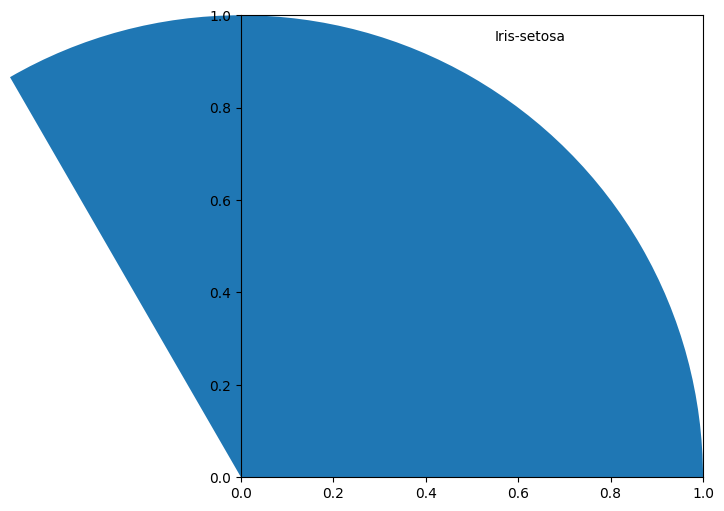

In [29]:
#Visualize the target class
plt.figure(figsize=(12,6))
plt.pie(x.values, labels=x.index, autopct='%1.1f%')
plt.show()

In [5]:
x = df.drop('Species', axis=1)
x

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,1,5.1,3.5,1.4,0.2
1,2,4.9,3.0,1.4,0.2
2,3,4.7,3.2,1.3,0.2
3,4,4.6,3.1,1.5,0.2
4,5,5.0,3.6,1.4,0.2
...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3
146,147,6.3,2.5,5.0,1.9
147,148,6.5,3.0,5.2,2.0
148,149,6.2,3.4,5.4,2.3


In [6]:
y = df['Species']
y

0         Iris-setosa
1         Iris-setosa
2         Iris-setosa
3         Iris-setosa
4         Iris-setosa
            ...      
145    Iris-virginica
146    Iris-virginica
147    Iris-virginica
148    Iris-virginica
149    Iris-virginica
Name: Species, Length: 150, dtype: object

In [7]:
x.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,1,5.1,3.5,1.4,0.2
1,2,4.9,3.0,1.4,0.2
2,3,4.7,3.2,1.3,0.2
3,4,4.6,3.1,1.5,0.2
4,5,5.0,3.6,1.4,0.2


In [8]:
from sklearn.model_selection import train_test_split

In [14]:
# train_test_split(data, labels, test_size=0.2, random_state =42)
x_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [15]:
x_train.shape

(120, 5)

In [16]:
x_test.shape

NameError: name 'x_test' is not defined

In [34]:
from sklearn.linear_model import LogisticRegression

In [36]:
classifier = LogisticRegression()

In [37]:
classifier.fit(x_train,y_train)

NameError: name 'x_train' is not defined